Sales Analytics

In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [148]:
df = pd.read_csv("/content/sales_analytics.csv")

In [149]:
df.head()

,Order_ID,Order_Date,Region,Category,Product_Name,Quantity,Unit_Price_USD,Total_Sales_USD
0,56551.0,2025-10-08,East,Furniture,Desk Chair,1.0,150.0,150.0
1,57748.0,2025-05-05,South,Furniture,Desk Chair,2.0,150.0,300.0
2,58554.0,2026-05-26,West,Office Supplies,Notebook,5.0,8.0,40.0
3,57192.0,2026-06-26,South,Electronics,Laptop,2.0,1200.0,2400.0
4,50501.0,2026-06-28,North,Clothing,Backpack,9.0,60.0,540.0


In [150]:
# 1. What is the total revenue and total quantity of items sold across each region?
Total_rev = df.groupby("Region").agg(
    Total_Revenue=("Total_Sales_USD", "sum"),Total_Quantity=("Quantity", "sum")).reset_index()

Total_rev

,Region,Total_Revenue,Total_Quantity
0,East,4586640.0,15707.0
1,North,5036518.0,16012.0
2,South,4755954.0,15294.0
3,West,4307937.0,14629.0


In [151]:
# 2. Which product categories and specific product names generate the highest total sales?
cat_prod_sales = df.groupby(["Category", "Product_Name"])["Total_Sales_USD"].sum().reset_index()

top_sales = cat_prod_sales.sort_values(by="Total_Sales_USD", ascending=False).head(5).reset_index()
print("Highest Total Sales By Product & Category")
top_sales

Highest Total Sales By Product & Category


,index,Category,Product_Name,Total_Sales_USD
0,4,Electronics,Laptop,5790000.0
1,9,Furniture,Conference Table,4857600.0
2,6,Electronics,Smartphone,3912800.0
3,11,Furniture,Standing Desk,2287000.0
4,7,Electronics,Tablet,2061000.0


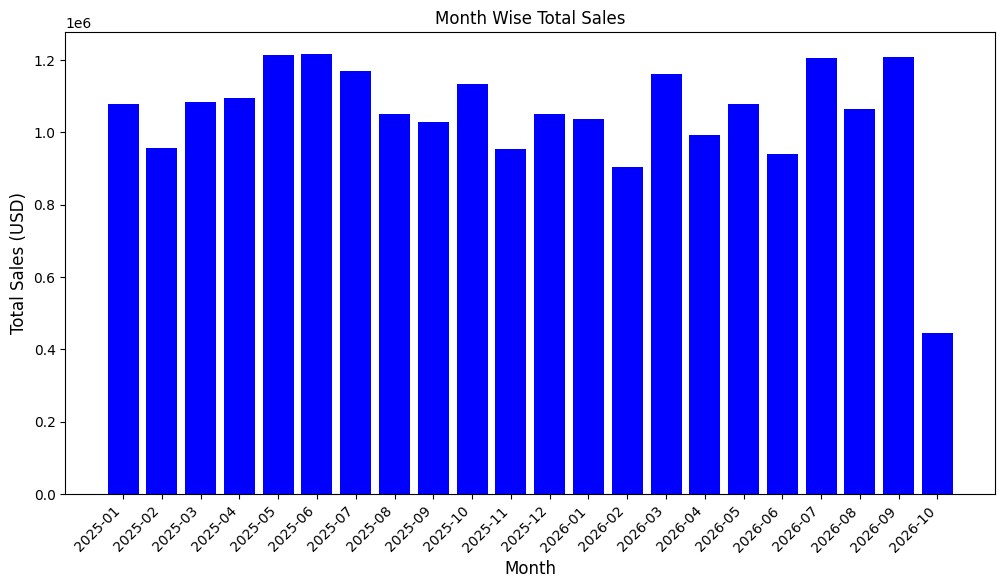

In [152]:
# 3. How do monthly sales trends fluctuate over time based on the order dates?

df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
monthly_sales = df.groupby(df['Order_Date'].dt.to_period('M'))['Total_Sales_USD'].sum().reset_index()

monthly_sales["Order_Date"] = monthly_sales["Order_Date"].astype(str)
plt.figure(figsize=(12, 6))
plt.bar(monthly_sales["Order_Date"], monthly_sales["Total_Sales_USD"], color="blue")
plt.title("Month Wise Total Sales", fontsize=12)
plt.xlabel("Month",fontsize=12)
plt.ylabel("Total Sales (USD)", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.show()

In [153]:
# 4. What percentage of total orders contain missing values or data inconsistencies,
# and how were they cleaned?

pct_missing = (df.isnull().any(axis=1).sum() / len(df)) * 100
print(f"Missing/Inconsistent Rows: {pct_missing:.2f}%")

df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce").fillna(pd.NaT)
df["Category"] = df["Category"].fillna("Unknown")

Missing/Inconsistent Rows: 30.73%


In [154]:
# 5. Which region has the highest average order value (AOV) per transaction?

region_aov = df.groupby("Region").agg(
    Total_Revenue=("Total_Sales_USD", "sum"),Total_Orders=("Total_Sales_USD", "count"),
    AVG_Order_Value=("Total_Sales_USD", "mean"))

region_aov = region_aov.sort_values(by="AVG_Order_Value", ascending=False)

print("Highest AVG Value By Region")
region_aov

Highest AVG Value By Region


,Total_Revenue,Total_Orders,AVG_Order_Value
Region,,,
South,4755954.0,1834,2593.213740
North,5036518.0,1944,2590.801440
East,4586640.0,1908,2403.899371
West,4307937.0,1842,2338.728013
